# Caffeine, Work, Sleep, and Well-Being: Simplified Analysis

**Goal:** build one clean participant-level dataset, compare caffeine consumption by age and sex, examine pairwise caffeine/outcome relationships, and prepare separate machine-learning models for sleep, work hours, focus difficulty, and worry/anxiety frequency.

This notebook keeps the core data-loading, cleaning, demographic comparisons, pairwise relationship checks, and machine-learning steps. It avoids repeated plots, duplicate statistical models, food-record deep dives, and extensive sensitivity analyses.

**Important limitations**
- Caffeine is based on NHANES Day 1 dietary recall, not a person's usual long-term intake.
- The worry/anxiety questions are indicators of worry/anxiety frequency, not a validated stress scale.
- This is observational data, so results show associations/predictions, not cause and effect.
- The models below are exploratory and do not account for the full NHANES complex survey design.

## 1. Import libraries and load the required NHANES files

Only the files needed for the four research outcomes and basic demographic controls are loaded. Update `data_path` if your project folder is in a different location.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import spearmanr
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, accuracy_score, f1_score, classification_report)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

data_path = Path(r"C:\Users\Savio\OneDrive\Desktop\DS2\Project 3")

dietary_df = pd.read_sas(data_path / "DR1IFF_J.xpt", format = "xport")
occupation_df = pd.read_sas(data_path / "OCQ_J.xpt", format = "xport")
sleep_df = pd.read_sas(data_path / "SLQ_J.xpt", format = "xport")
mental_df = pd.read_sas(data_path / "DPQ_J.xpt", format = "xport")
worry_df = pd.read_sas(data_path / "DLQ_J.xpt", format = "xport")
demographics_df = pd.read_sas(data_path / "DEMO_J.xpt", format = "xport")

## 2. Calculate each participant's Day 1 caffeine intake

Sum caffeine across the participant's reported food and beverage items. This should match NHANES's official Day 1 total (`DR1TCAFF`) when checked against the total-intake file.

In [2]:
caffeine_total = (dietary_df.groupby("SEQN")["DR1ICAFF"].sum(min_count = 1).reset_index().rename(columns = {"DR1ICAFF": "Caffeine_mg"}))

# Optional verification against NHANES's official total.
dietary_totals = pd.read_sas(data_path / "DR1TOT_J.xpt", format="xport")
caffeine_check = caffeine_total.merge(dietary_totals[["SEQN", "DR1TCAFF"]], on = "SEQN", how = "inner")
caffeine_check["Difference"] = caffeine_check["Caffeine_mg"] - caffeine_check["DR1TCAFF"]

print("Participants checked:", len(caffeine_check))
print("Largest absolute difference (mg):", caffeine_check["Difference"].abs().max())

Participants checked: 7640
Largest absolute difference (mg): 1.8351858179575695e-77


## 3. Select, clean, and combine the variables

Special missing-value codes are changed to missing values. The questionnaire responses are kept as ordered numeric scores for machine learning.

In [3]:
occupation = occupation_df[["SEQN", "OCQ180"]].copy()
sleep = sleep_df[["SEQN", "SLD012"]].copy()
mental = mental_df[["SEQN", "DPQ070"]].copy()
worry = worry_df[["SEQN", "DLQ100"]].copy()
demographics = demographics_df[["SEQN", "RIDAGEYR", "RIAGENDR"]].copy()

In [4]:
# Convert selected fields to numeric.
for frame in [occupation, sleep, mental, worry, demographics]:
    for column in frame.columns:
        if column != "SEQN":
            frame[column] = pd.to_numeric(frame[column], errors = "coerce")

# Work hours: 77777 and 99999 are nonresponse codes.
occupation["OCQ180"] = occupation["OCQ180"].replace([77777, 99999], np.nan)

# Focus difficulty: 0-3 are valid responses; 7 and 9 are nonresponse codes.
mental["DPQ070"] = mental["DPQ070"].replace([7, 9], np.nan)
mental.loc[mental["DPQ070"].abs() < 1e-50, "DPQ070"] = 0

# Worry/anxiety frequency: 1=Daily, 2=Weekly, 3=Monthly,
# 4=A few times a year, 5=Never. 7 and 9 are nonresponse codes.
worry["DLQ100"] = worry["DLQ100"].replace([7, 9], np.nan)

In [ ]:
# Build one row per participant.
final_df = (caffeine_total
    .merge(occupation, on = "SEQN", how = "left")
    .merge(sleep, on = "SEQN", how = "left")
    .merge(mental, on = "SEQN", how = "left")
    .merge(worry, on = "SEQN", how = "left")
    .merge(demographics, on = "SEQN", how = "left"))

final_df = final_df.rename(columns = {
    "OCQ180": "Work_Hours",
    "SLD012": "Sleep_Hours",
    "DPQ070": "Focus_Difficulty",
    "DLQ100": "Worry_Frequency",
    "RIDAGEYR": "Age",
    "RIAGENDR": "Sex"})

# Convert sex codes to readable categories.
final_df["Sex"] = final_df["Sex"].map({1: "Male", 2: "Female"})

# Tiny floating-point values from SAS files should be treated as zero.
final_df.loc[final_df["Caffeine_mg"].abs() < 1e-50, "Caffeine_mg"] = 0

final_df.head()

,SEQN,Caffeine_mg,Work_Hours,Sleep_Hours,Focus_Difficulty,Worry_Frequency,Age,Sex
0,93704.0,8.0,NaN,NaN,NaN,NaN,2.0,Male
1,93705.0,361.0,30.0,8.0,0.0,4.0,66.0,Female
2,93706.0,0.0,NaN,10.5,0.0,5.0,18.0,Male
3,93707.0,21.0,NaN,NaN,NaN,NaN,13.0,Male
4,93708.0,33.0,NaN,8.0,0.0,5.0,66.0,Female


## 4. Check the combined dataset

Check for duplicate participant IDs, missing values, and basic ranges before modeling. NHANES records 80 work hours as **80 or more**, not necessarily exactly 80.

In [6]:
print("Dataset shape:", final_df.shape)
print("Duplicate participant IDs:", final_df["SEQN"].duplicated().sum())

display(final_df[["Caffeine_mg", "Work_Hours", "Sleep_Hours", "Focus_Difficulty", "Worry_Frequency", "Age"]].describe().T)

display(final_df.isna().sum().to_frame("Missing values"))
print("Work hours recorded as 80 (80 or more):", (final_df["Work_Hours"] == 80).sum())

Dataset shape: (7640, 8)
Duplicate participant IDs: 0


,count,mean,std,min,25%,50%,75%,max
Caffeine_mg,7598.0,98.758357,183.328424,0.000000e+00,0.0,33.0,141.0,4320.0
Work_Hours,2718.0,38.692789,14.388946,5.000000e+00,30.0,40.0,45.0,80.0
Sleep_Hours,5224.0,7.634284,1.658936,2.000000e+00,6.5,7.5,8.5,14.0
Focus_Difficulty,4787.0,0.258408,0.664192,0.000000e+00,0.0,0.0,0.0,3.0
Worry_Frequency,4912.0,3.374593,1.382671,1.000000e+00,2.0,4.0,4.0,5.0
Age,7640.0,35.088613,25.154345,5.397605e-79,12.0,33.0,58.0,80.0


,Missing values
SEQN,0
Caffeine_mg,42
Work_Hours,4922
Sleep_Hours,2416
Focus_Difficulty,2853
Worry_Frequency,2728
Age,0
Sex,0


Work hours recorded as 80 (80 or more): 39


## 5. A few essential visual checks

These plots are only for understanding the distributions and spotting obvious data issues. They are not evidence of causation.

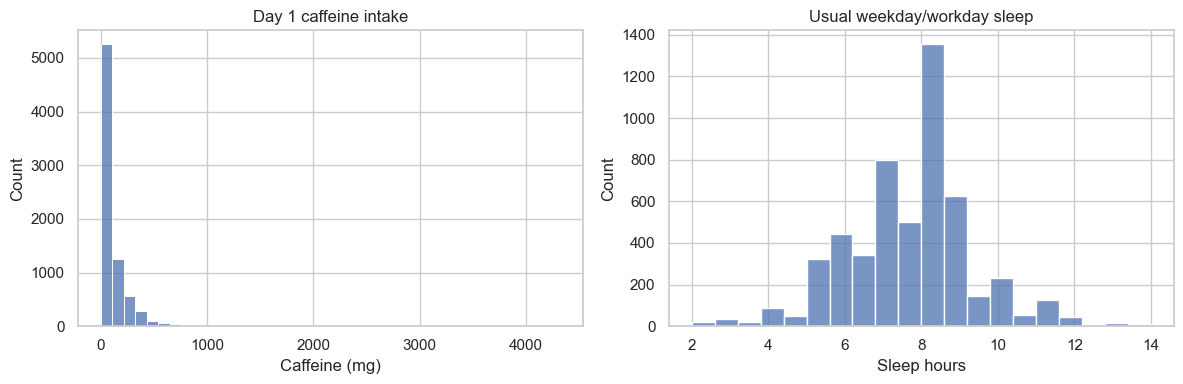

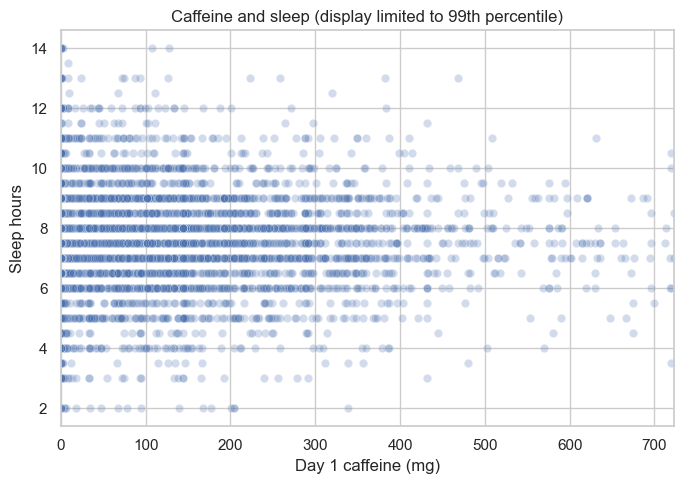

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(final_df["Caffeine_mg"].dropna(), bins = 40, ax = axes[0])
axes[0].set_title("Day 1 caffeine intake")
axes[0].set_xlabel("Caffeine (mg)")

sns.histplot(final_df["Sleep_Hours"].dropna(), bins = 20, ax = axes[1])
axes[1].set_title("Usual weekday/workday sleep")
axes[1].set_xlabel("Sleep hours")

plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.scatterplot(data = final_df, x = "Caffeine_mg", y = "Sleep_Hours", alpha = 0.25)
plt.xlim(0, final_df["Caffeine_mg"].quantile(0.99))
plt.title("Caffeine and sleep (display limited to 99th percentile)")
plt.xlabel("Day 1 caffeine (mg)")
plt.ylabel("Sleep hours")
plt.tight_layout()
plt.show()

## 6. Compare caffeine consumption by age and sex

This section describes how Day 1 caffeine consumption differs across adult age groups and between males and females. It also shows the age-by-sex groups. These are descriptive sample comparisons, not causal conclusions.

Age groups are limited to adults (18+): 18–29, 30–39, 40–49, 50–59, and 60+.


In [8]:
# Use adults with known age, sex, and caffeine intake for these comparisons.
demo_df = final_df.loc[final_df["Age"].ge(18) & final_df["Age"].notna() & final_df["Sex"].notna() & final_df["Caffeine_mg"].notna()].copy()

demo_df["Age_Group"] = pd.cut(demo_df["Age"], bins = [18, 30, 40, 50, 60, np.inf], labels = ["18-29", "30-39", "40-49", "50-59", "60+"], right = False)

print("Adult participants included:", len(demo_df))

print("Caffeine consumption by age group:")
display(demo_df.groupby("Age_Group", observed = True)["Caffeine_mg"].agg(Participants = "count", Mean = "mean", Median = "median", SD = "std").round(2))

print("Caffeine consumption by sex:")
display(demo_df.groupby("Sex")["Caffeine_mg"].agg(Participants = "count", Mean = "mean", Median = "median", SD = "std").round(2))

print("Caffeine consumption by age group and sex:")
age_sex_caffeine = (demo_df.groupby(["Age_Group", "Sex"], observed = True)["Caffeine_mg"].agg(Participants = "count", Mean = "mean", Median = "median").round(2))
display(age_sex_caffeine)

Adult participants included: 4982
Caffeine consumption by age group:


,Participants,Mean,Median,SD
Age_Group,,,,
18-29,935,83.57,36.0,129.54
30-39,735,133.09,82.0,203.25
40-49,707,178.30,113.0,297.87
50-59,794,168.38,108.0,255.67
60+,1811,147.33,103.0,176.30


Caffeine consumption by sex:


,Participants,Mean,Median,SD
Sex,,,,
Female,2556,122.8,78.0,183.67
Male,2426,160.2,104.0,234.69


Caffeine consumption by age group and sex:


Participants    Mean  Median
Age_Group Sex                                 
18-29     Female           481   79.65    36.0
          Male             454   87.72    36.5
30-39     Female           406  106.35    69.5
          Male             329  166.09   108.0
40-49     Female           367  156.82   102.0
          Male             340  201.49   131.0
50-59     Female           419  151.65    93.0
          Male             375  187.07   135.0
60+       Female           883  126.03    96.0
          Male             928  167.59   119.5

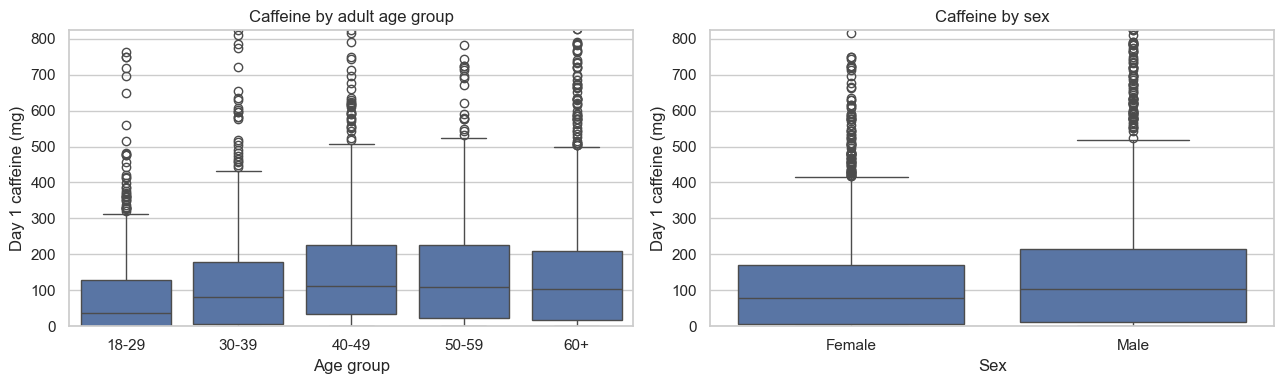

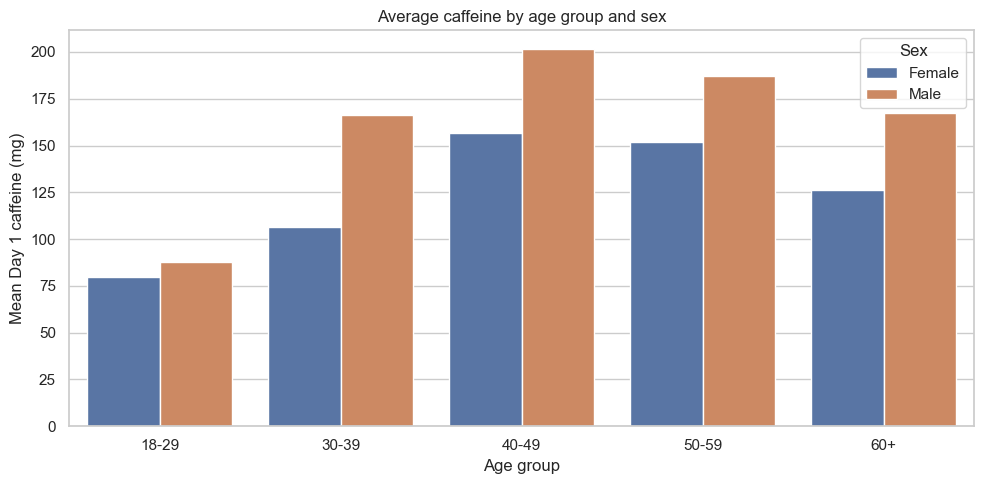

In [9]:
# Visual comparisons. The x-axis is limited to the 99th percentile for readability;
# the underlying data are not removed or changed.
caffeine_plot_max = demo_df["Caffeine_mg"].quantile(0.99)

fig, axes = plt.subplots(1, 2, figsize = (13, 4))
sns.boxplot(data = demo_df, x = "Age_Group", y = "Caffeine_mg", ax = axes[0])
axes[0].set_ylim(0, caffeine_plot_max)
axes[0].set_title("Caffeine by adult age group")
axes[0].set_xlabel("Age group")
axes[0].set_ylabel("Day 1 caffeine (mg)")

sns.boxplot(data = demo_df, x = "Sex", y = "Caffeine_mg", ax = axes[1])
axes[1].set_ylim(0, caffeine_plot_max)
axes[1].set_title("Caffeine by sex")
axes[1].set_xlabel("Sex")
axes[1].set_ylabel("Day 1 caffeine (mg)")

plt.tight_layout()
plt.show()

plt.figure(figsize = (10, 5))
sns.barplot(data = demo_df, x = "Age_Group", y = "Caffeine_mg", hue = "Sex", errorbar = None)
plt.title("Average caffeine by age group and sex")
plt.xlabel("Age group")
plt.ylabel("Mean Day 1 caffeine (mg)")
plt.tight_layout()
plt.show()


## 7. Check caffeine's relationship with each outcome separately

Each relationship uses participants who have both caffeine and that specific outcome available. Missing information for another outcome does not remove a participant from this pairwise analysis.

Spearman correlation is used because the outcomes include skewed or ordered questionnaire responses. The results describe association, not cause and effect.


In [ ]:
outcome_columns = {
    "Sleep hours": "Sleep_Hours",
    "Work hours": "Work_Hours",
    "Focus difficulty": "Focus_Difficulty",
    "Worry/anxiety frequency": "Worry_Frequency"}

pairwise_results = []

for outcome_name, outcome_column in outcome_columns.items():
    pair = final_df[["Caffeine_mg", outcome_column]].dropna()
    rho, p_value = spearmanr(pair["Caffeine_mg"], pair[outcome_column])

    pairwise_results.append({"Outcome": outcome_name, "Participants": len(pair), "Spearman correlation": rho, "P-value": p_value})

pairwise_results_df = pd.DataFrame(pairwise_results)
display(pairwise_results_df.round(4))

,Outcome,Participants,Spearman correlation,P-value
0,Sleep hours,5224,-0.0559,0.0001
1,Work hours,2718,0.0931,0.0000
2,Focus difficulty,4787,0.0102,0.4825
3,Worry/anxiety frequency,4912,-0.0431,0.0025


## 8. Compare outcomes across caffeine-intake ranges

This section gives an easy-to-read comparison of participants across caffeine-intake ranges. The ranges are descriptive groups, not recommended caffeine limits. Sleep and work are summarized with their mean and median. Focus and worry/anxiety are shown as response distributions because they are ordered questionnaire categories.

In [ ]:
# Create descriptive caffeine-intake ranges. Values above 500 mg are kept in one group.
caffeine_bins = [-0.001, 0, 100, 200, 300, 400, 500, np.inf]
caffeine_labels = ["0 mg", "1-100 mg", "101-200 mg", "201-300 mg", "301-400 mg", "401-500 mg", "Over 500 mg"]

dose_df = final_df.copy()
dose_df["Caffeine_Range"] = pd.cut(dose_df["Caffeine_mg"], bins = caffeine_bins, labels = caffeine_labels, include_lowest = True)

print("Participants in each caffeine range:")
display(dose_df.groupby("Caffeine_Range", observed = False)["Caffeine_mg"].agg(Participants = "count", Mean_Caffeine_mg = "mean").round(1))

print("Sleep and work outcomes by caffeine range:")
dose_summary = (dose_df.groupby("Caffeine_Range", observed = False).agg(Participants = ("Caffeine_mg", "count"),
        Mean_Sleep_Hours = ("Sleep_Hours", "mean"),
        Median_Sleep_Hours = ("Sleep_Hours", "median"),
        Mean_Work_Hours = ("Work_Hours", "mean"),
        Median_Work_Hours = ("Work_Hours", "median")).round(2))
display(dose_summary)

print("Focus difficulty response percentages by caffeine range:")
focus_distribution = pd.crosstab(dose_df["Caffeine_Range"], dose_df["Focus_Difficulty"], normalize = "index").mul(100).round(1)
display(focus_distribution)

print("Worry/anxiety frequency response percentages by caffeine range:")
worry_distribution = pd.crosstab(dose_df["Caffeine_Range"], dose_df["Worry_Frequency"], normalize = "index").mul(100).round(1)
display(worry_distribution)

print("Focus response codes: 0-3, where higher values indicate more frequent concentration difficulty.")
print("Worry response codes: 1 = Daily, 2 = Weekly, 3 = Monthly, 4 = A few times a year, 5 = Never.")

Participants in each caffeine range:


,Participants,Mean_Caffeine_mg
Caffeine_Range,,
0 mg,1919,0.0
1-100 mg,3183,32.0
101-200 mg,1264,142.4
201-300 mg,613,245.5
301-400 mg,320,344.8
401-500 mg,114,442.9
Over 500 mg,185,849.3


Sleep and work outcomes by caffeine range:


,Participants,Mean_Sleep_Hours,Median_Sleep_Hours,Mean_Work_Hours,Median_Work_Hours
Caffeine_Range,,,,,
0 mg,1919,7.70,8.0,37.67,40.0
1-100 mg,3183,7.72,8.0,37.45,40.0
101-200 mg,1264,7.60,7.5,39.92,40.0
201-300 mg,613,7.50,7.5,39.33,40.0
301-400 mg,320,7.48,7.5,40.20,40.0
401-500 mg,114,7.67,8.0,39.72,40.0
Over 500 mg,185,7.32,7.5,41.61,40.0


Focus difficulty response percentages by caffeine range:


Focus_Difficulty,0.0,1.0,2.0,3.0
Caffeine_Range,,,,
0 mg,83.9,10.1,2.3,3.8
1-100 mg,83.3,10.5,3.0,3.2
101-200 mg,84.7,10.1,2.3,2.9
201-300 mg,83.0,10.0,4.2,2.8
301-400 mg,85.9,10.3,2.6,1.3
401-500 mg,80.0,13.6,2.7,3.6
Over 500 mg,74.9,11.7,7.8,5.6


Worry/anxiety frequency response percentages by caffeine range:


Worry_Frequency,1.0,2.0,3.0,4.0,5.0
Caffeine_Range,,,,,
0 mg,13.5,12.6,14.2,32.9,26.9
1-100 mg,14.5,14.1,12.5,34.6,24.2
101-200 mg,13.6,14.4,13.6,35.9,22.5
201-300 mg,17.4,15.1,10.7,35.6,21.2
301-400 mg,17.9,15.3,8.0,34.2,24.6
401-500 mg,21.2,17.7,9.7,30.1,21.2
Over 500 mg,24.3,16.6,7.7,24.3,27.1


Focus response codes: 0-3, where higher values indicate more frequent concentration difficulty.
Worry response codes: 1=Daily, 2=Weekly, 3=Monthly, 4=A few times a year, 5=Never.


## 9. Visualize outcomes across caffeine-intake ranges

The first two plots show average sleep and work hours across caffeine ranges. The next two show the percentage of participants in each focus and worry/anxiety response category. These are descriptive comparisons; they do not show that caffeine causes the outcomes.

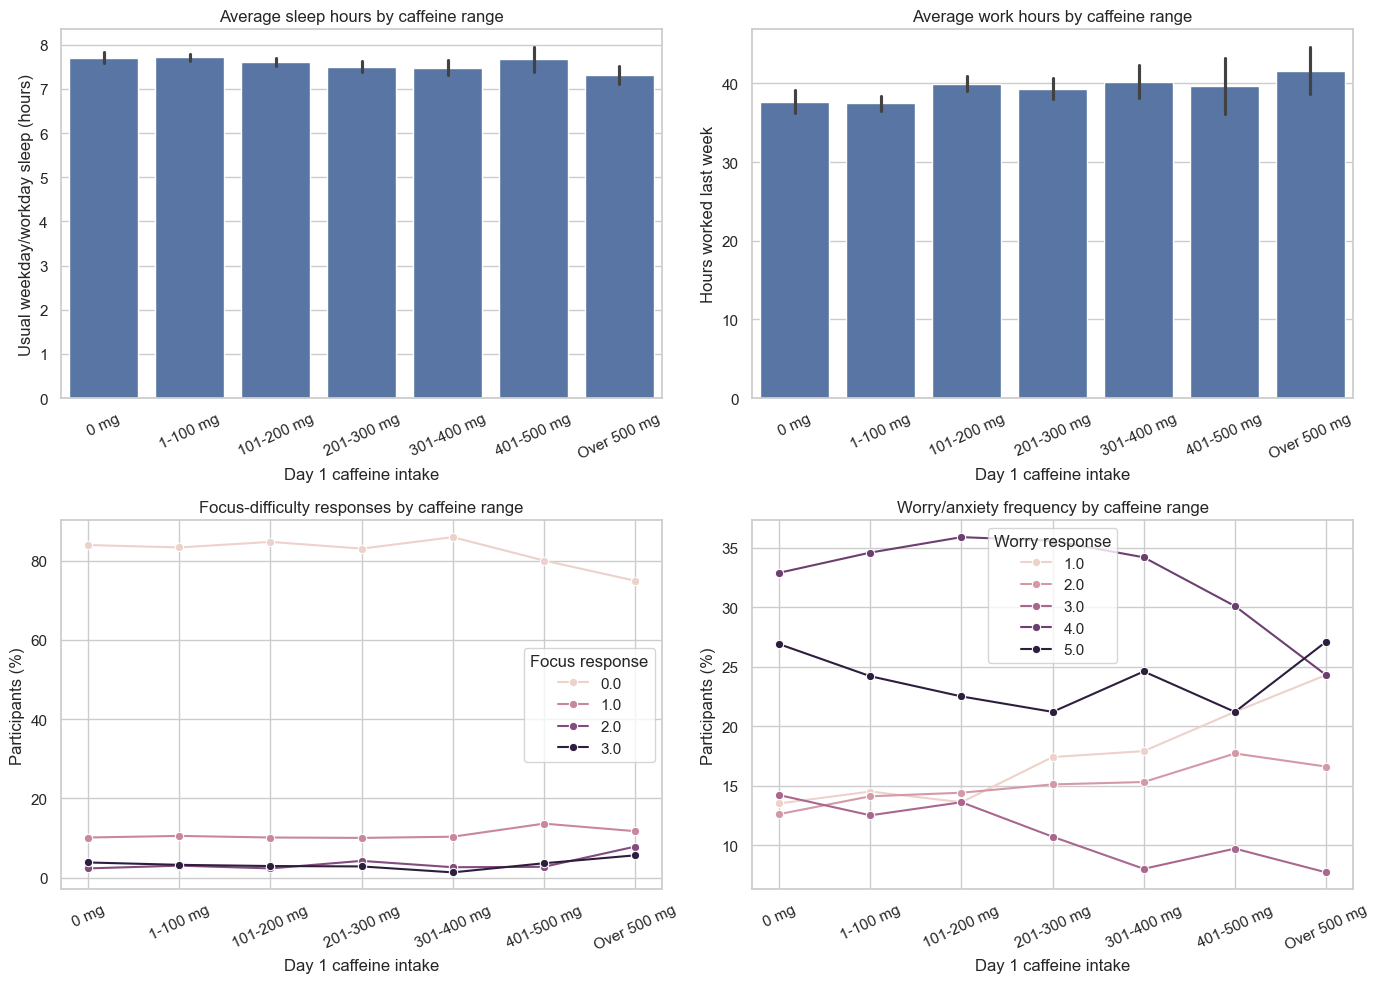

For focus, higher response codes indicate more frequent difficulty.
For worry/anxiety, lower response codes indicate more frequent worry/anxiety.


In [ ]:
fig, axes = plt.subplots(2, 2, figsize = (14, 10))

sns.barplot(data = dose_df, x = "Caffeine_Range", y = "Sleep_Hours", errorbar = ("ci", 95), ax = axes[0, 0])
axes[0, 0].set_title("Average sleep hours by caffeine range")
axes[0, 0].set_xlabel("Day 1 caffeine intake")
axes[0, 0].set_ylabel("Usual weekday/workday sleep (hours)")
axes[0, 0].tick_params(axis = "x", rotation = 25)

sns.barplot(data = dose_df, x = "Caffeine_Range", y = "Work_Hours", errorbar = ("ci", 95), ax = axes[0, 1])
axes[0, 1].set_title("Average work hours by caffeine range")
axes[0, 1].set_xlabel("Day 1 caffeine intake")
axes[0, 1].set_ylabel("Hours worked last week")
axes[0, 1].tick_params(axis = "x", rotation = 25)

focus_plot = focus_distribution.reset_index().melt(id_vars = "Caffeine_Range", var_name = "Focus response", value_name = "Percent")
sns.lineplot(data = focus_plot, x = "Caffeine_Range", y = "Percent", hue = "Focus response", marker = "o", ax = axes[1, 0])
axes[1, 0].set_title("Focus-difficulty responses by caffeine range")
axes[1, 0].set_xlabel("Day 1 caffeine intake")
axes[1, 0].set_ylabel("Participants (%)")
axes[1, 0].tick_params(axis = "x", rotation = 25)

worry_plot = worry_distribution.reset_index().melt(id_vars = "Caffeine_Range", var_name = "Worry response", value_name = "Percent")
sns.lineplot(data = worry_plot, x = "Caffeine_Range", y = "Percent", hue = "Worry response", marker = "o", ax = axes[1, 1])
axes[1, 1].set_title("Worry/anxiety frequency by caffeine range")
axes[1, 1].set_xlabel("Day 1 caffeine intake")
axes[1, 1].set_ylabel("Participants (%)")
axes[1, 1].tick_params(axis = "x", rotation = 25)

plt.tight_layout()
plt.show()

print("For focus, higher response codes indicate more frequent difficulty.")
print("For worry/anxiety, lower response codes indicate more frequent worry/anxiety.")

## 10. Prepare caffeine-focused machine-learning models

The goal here is to examine whether caffeine intake can help estimate each outcome.

For every outcome, we compare three Random Forest models:
- **Caffeine only:** uses caffeine intake as the predictor.
- **Age and sex:** provides a demographic comparison.
- **Caffeine, age, and sex:** checks whether caffeine adds predictive information when age and sex are included.

Sleep and work hours use regression. Focus difficulty and worry/anxiety frequency use classification because they are ordered questionnaire response categories. Each outcome is modeled separately, and missing target values are excluded only from that outcome's model. Missing predictors are imputed within each training pipeline.

The models are exploratory. Their estimates describe patterns in this sample and should not be interpreted as causal effects or guaranteed individual outcomes.

In [ ]:
ml_df = final_df.copy()
ml_df["Caffeine_mg"] = pd.to_numeric(ml_df["Caffeine_mg"], errors = "coerce")

targets = {
    "Sleep hours": ("Sleep_Hours", "regression"),
    "Work hours": ("Work_Hours", "regression"),
    "Focus difficulty": ("Focus_Difficulty", "classification"),
    "Worry/anxiety frequency": ("Worry_Frequency", "classification")}

predictor_sets = {
    "Caffeine only": ["Caffeine_mg"],
    "Age and sex": ["Age", "Sex"],
    "Caffeine + age + sex": ["Caffeine_mg", "Age", "Sex"]}

def make_preprocessor(X):
    numeric_features = X.select_dtypes(include=np.number).columns.tolist()
    categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

    transformers = []
    if numeric_features:
        transformers.append(("numeric", SimpleImputer(strategy = "median"), numeric_features))
    if categorical_features:
        transformers.append(("categorical", Pipeline([("imputer", SimpleImputer(strategy = "most_frequent")), ("onehot", OneHotEncoder(handle_unknown = "ignore"))]), categorical_features))
    return ColumnTransformer(transformers = transformers)

## 11. Train and compare the models

All three models for a given outcome use the same participants and the same train/test split. This makes their test performance directly comparable. A simple baseline is also included to show whether the Random Forest learns a useful pattern beyond a basic guess.

In [ ]:
model_results = []
trained_models = {}
test_data = {}

for outcome_name, (target, task) in targets.items():
    available = ml_df.dropna(subset=[target]).copy()
    y = available[target]

    # Use the same split for every predictor set for this outcome.
    all_predictors = ["Caffeine_mg", "Age", "Sex"]
    X_all = available[all_predictors]
    stratify_values = (y if task == "classification" and y.value_counts().min() >= 2 else None)

    X_train_all, X_test_all, y_train, y_test = train_test_split(X_all, y, test_size = 0.20, random_state = 42, stratify = stratify_values)

    if task == "regression":
        baseline = DummyRegressor(strategy = "mean")
    else:
        baseline = DummyClassifier(strategy = "most_frequent")

    baseline_predictors = ["Caffeine_mg"]
    baseline_pipe = Pipeline([("preprocess", make_preprocessor(X_train_all[baseline_predictors])), ("model", baseline)])
    baseline_pipe.fit(X_train_all[baseline_predictors], y_train)
    baseline_prediction = baseline_pipe.predict(X_test_all[baseline_predictors])

    if task == "regression":
        model_results.append({
            "Outcome": outcome_name, "Predictors": "Simple baseline",
            "Test participants": len(y_test),
            "MAE": mean_absolute_error(y_test, baseline_prediction),
            "RMSE": np.sqrt(mean_squared_error(y_test, baseline_prediction)),
            "R-squared": r2_score(y_test, baseline_prediction)})
    else:
        model_results.append({
            "Outcome": outcome_name, "Predictors": "Simple baseline",
            "Test participants": len(y_test),
            "Accuracy": accuracy_score(y_test, baseline_prediction),
            "Weighted F1": f1_score(y_test, baseline_prediction, average = "weighted", zero_division = 0)})

    trained_models[outcome_name] = {}
    test_data[outcome_name] = {}

    for model_label, predictors in predictor_sets.items():
        X_train = X_train_all[predictors]
        X_test = X_test_all[predictors]

        if task == "regression":
            estimator = RandomForestRegressor(n_estimators = 300, min_samples_leaf = 5, random_state = 42, n_jobs = -1)
        else:
            estimator = RandomForestClassifier(n_estimators = 300, min_samples_leaf = 5, class_weight = "balanced_subsample", random_state = 42, n_jobs = -1)

        pipeline = Pipeline([("preprocess", make_preprocessor(X_train)), ("model", estimator)])
        pipeline.fit(X_train, y_train)
        prediction = pipeline.predict(X_test)

        trained_models[outcome_name][model_label] = pipeline
        test_data[outcome_name][model_label] = (X_test, y_test, prediction)

        if task == "regression":
            model_results.append({
                "Outcome": outcome_name, "Predictors": model_label,
                "Test participants": len(y_test),
                "MAE": mean_absolute_error(y_test, prediction),
                "RMSE": np.sqrt(mean_squared_error(y_test, prediction)),
                "R-squared": r2_score(y_test, prediction)})
        else:
            model_results.append({
                "Outcome": outcome_name, "Predictors": model_label,
                "Test participants": len(y_test),
                "Accuracy": accuracy_score(y_test, prediction),
                "Weighted F1": f1_score(y_test, prediction, average = "weighted", zero_division = 0)})

model_results_df = pd.DataFrame(model_results)
display(model_results_df.round(4))

,Outcome,Predictors,Test participants,MAE,RMSE,R-squared,Accuracy,Weighted F1
0,Sleep hours,Simple baseline,1045,1.2372,1.6307,-0.0005,NaN,NaN
1,Sleep hours,Caffeine only,1045,1.2724,1.6787,-0.0604,NaN,NaN
2,Sleep hours,Age and sex,1045,1.2142,1.6138,0.0200,NaN,NaN
3,Sleep hours,Caffeine + age + sex,1045,1.2687,1.6828,-0.0656,NaN,NaN
4,Work hours,Simple baseline,544,10.5595,14.5418,-0.0003,NaN,NaN
5,Work hours,Caffeine only,544,10.8675,14.6864,-0.0203,NaN,NaN
6,Work hours,Age and sex,544,9.9054,13.4591,0.1431,NaN,NaN
7,Work hours,Caffeine + age + sex,544,10.2093,13.7065,0.1113,NaN,NaN
8,Focus difficulty,Simple baseline,958,NaN,NaN,NaN,0.8351,0.7600
9,Focus difficulty,Caffeine only,958,NaN,NaN,NaN,0.3309,0.4360


## 12. Compare machine-learning performance

For sleep and work, lower MAE and RMSE indicate smaller prediction errors. For focus and worry/anxiety, higher accuracy and weighted F1 indicate better classification performance. Compare models only within the same outcome. If caffeine-based models do not outperform the baseline or age-and-sex model, caffeine may provide limited predictive information in this dataset.

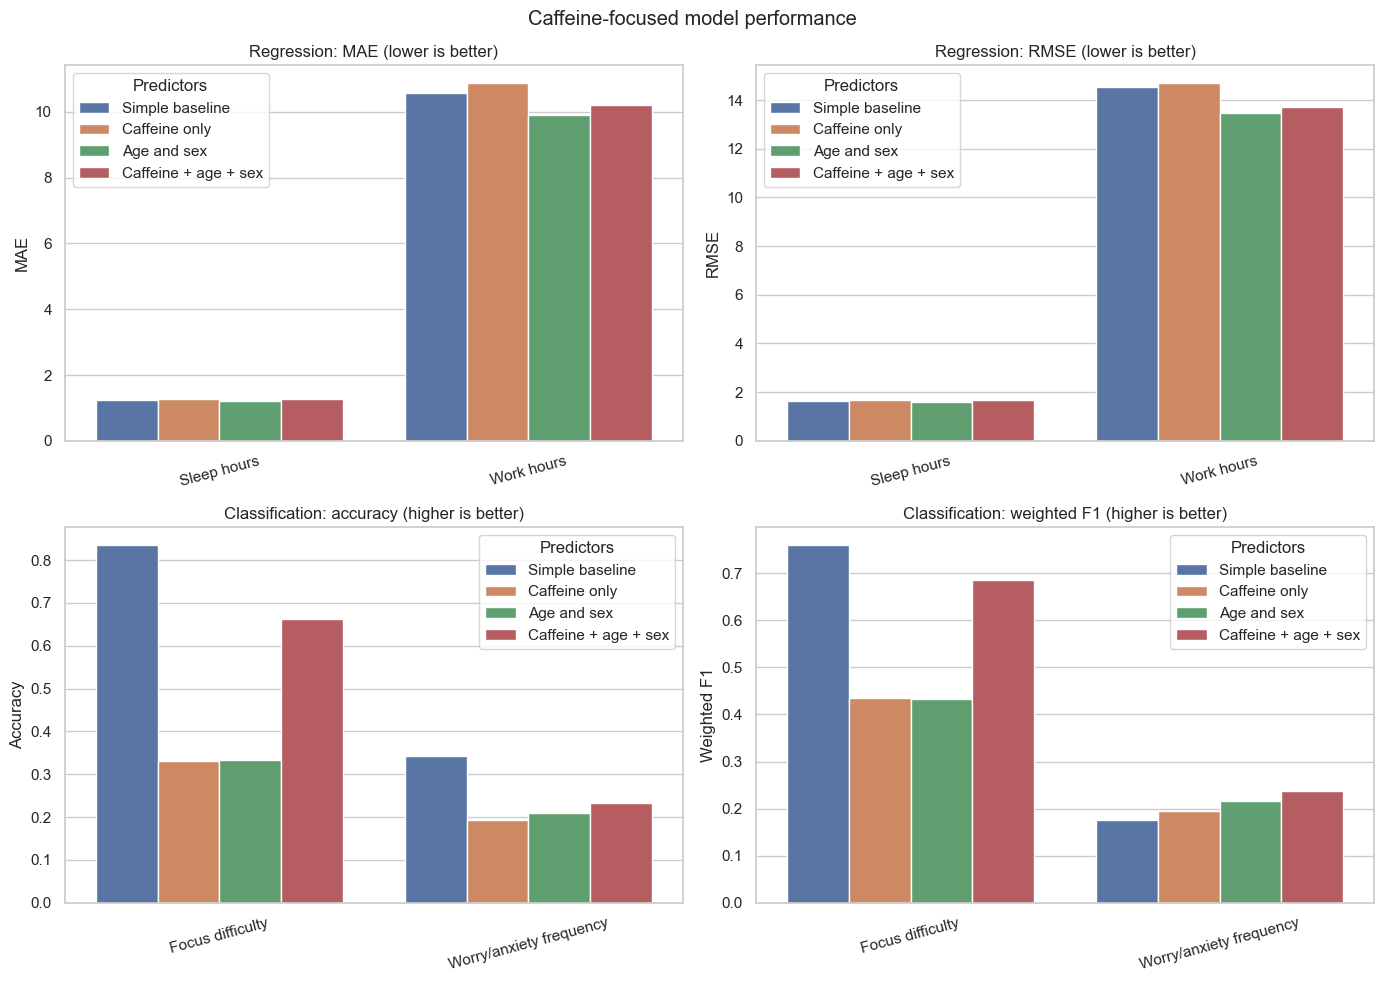

In [ ]:
regression_results = model_results_df[model_results_df["Outcome"].isin(["Sleep hours", "Work hours"])].copy()
classification_results = model_results_df[model_results_df["Outcome"].isin(["Focus difficulty", "Worry/anxiety frequency"])].copy()

fig, axes = plt.subplots(2, 2, figsize = (14, 10))

for ax, metric, title in [(axes[0, 0], "MAE", "Regression: MAE (lower is better)"), (axes[0, 1], "RMSE", "Regression: RMSE (lower is better)")]:
    sns.barplot(data = regression_results, x = "Outcome", y = metric, hue = "Predictors", ax = ax)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.tick_params(axis = "x", rotation = 15)

for ax, metric, title in [(axes[1, 0], "Accuracy", "Classification: accuracy (higher is better)"), (axes[1, 1], "Weighted F1", "Classification: weighted F1 (higher is better)")]:
    sns.barplot(data = classification_results, x = "Outcome", y = metric, hue = "Predictors", ax = ax)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.tick_params(axis = "x", rotation = 15)

plt.suptitle("Caffeine-focused model performance")
plt.tight_layout()
plt.show()

## 13. Estimate outcome patterns across caffeine levels

This section uses the model with caffeine, age, and sex to estimate how outcomes vary over a range of caffeine values. Age is held at the sample median and sex at the most common category so the caffeine pattern can be viewed while those two characteristics stay fixed.

For sleep and work, the lines show estimated hours. For focus and worry/anxiety, the lines show estimated probabilities of each response category. These are model-based estimates, not guaranteed outcomes for an individual. Estimates near the edges of the observed caffeine distribution are less reliable, so the graph is limited to the 95th percentile of observed caffeine intake.

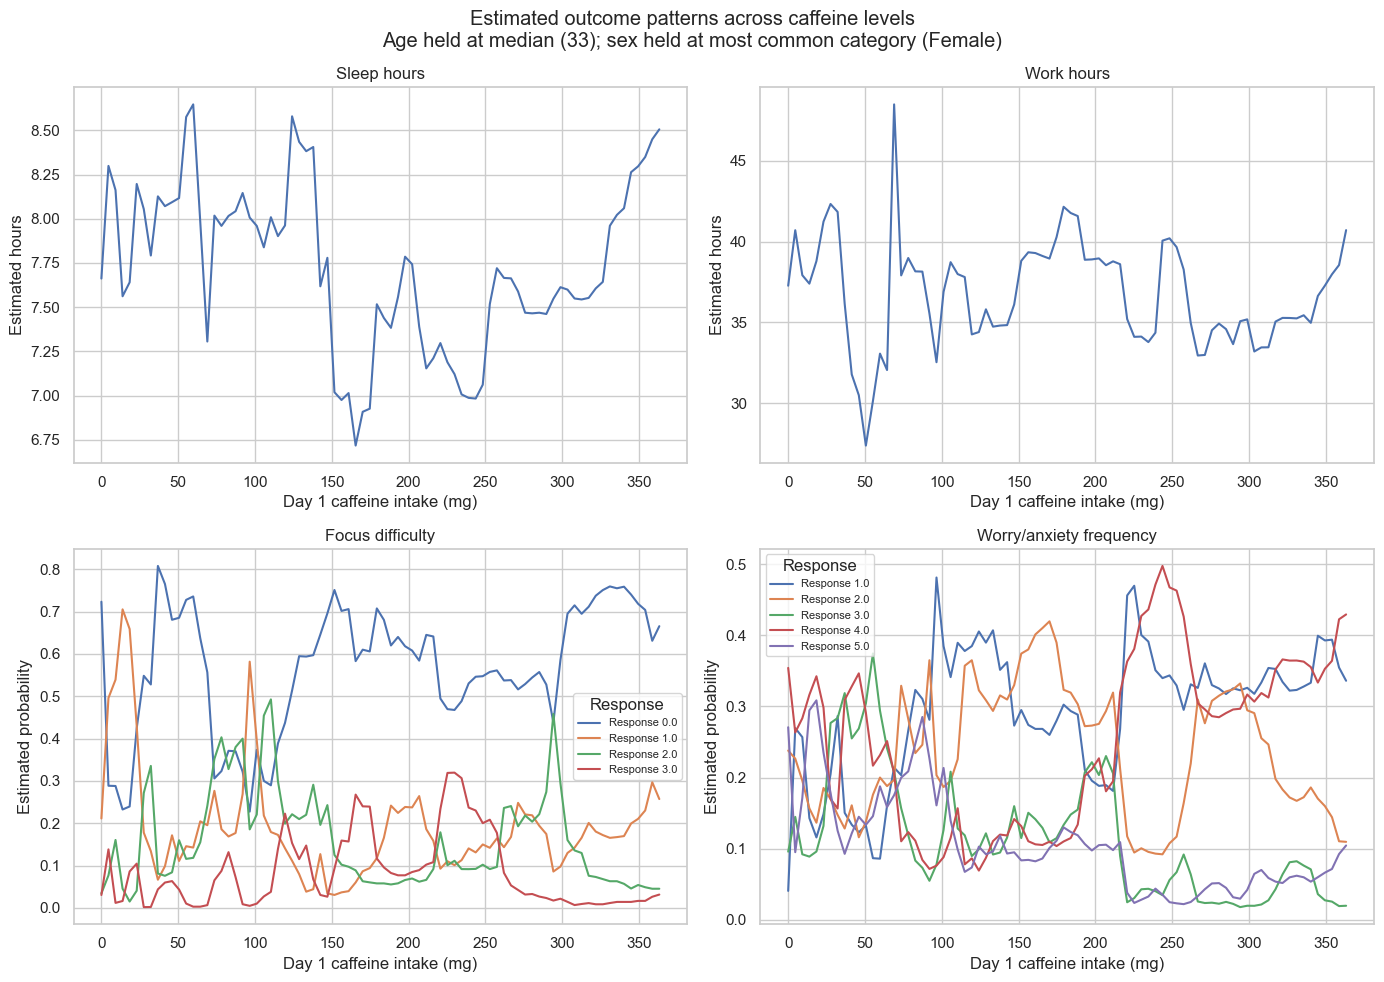

These curves show model estimates while age and sex are held constant.
They do not show causal effects or guarantee an individual's outcome.


In [ ]:
# Fit final caffeine + age + sex models on all available participants for each outcome.
final_dose_models = {}
for outcome_name, (target, task) in targets.items():
    predictors = ["Caffeine_mg", "Age", "Sex"]
    model_data = ml_df[predictors + [target]].dropna(subset = [target]).copy()
    X = model_data[predictors]
    y = model_data[target]

    if task == "regression":
        estimator = RandomForestRegressor(n_estimators = 300, min_samples_leaf = 5, random_state = 42, n_jobs = -1)
    else:
        estimator = RandomForestClassifier(n_estimators = 300, min_samples_leaf = 5, class_weight = "balanced_subsample", random_state = 42, n_jobs = -1)

    pipeline = Pipeline([("preprocess", make_preprocessor(X)), ("model", estimator)])
    pipeline.fit(X, y)
    final_dose_models[outcome_name] = pipeline

# Create a realistic caffeine range and hold age/sex constant.
caffeine_max = ml_df["Caffeine_mg"].quantile(0.95)
caffeine_grid = np.linspace(ml_df["Caffeine_mg"].min(), caffeine_max, 80)
reference_age = ml_df["Age"].median()
reference_sex = ml_df["Sex"].mode().iloc[0]

dose_prediction_input = pd.DataFrame({"Caffeine_mg": caffeine_grid, "Age": reference_age, "Sex": reference_sex})

fig, axes = plt.subplots(2, 2, figsize = (14, 10))
axes = axes.flatten()

for ax, (outcome_name, (target, task)) in zip(axes, targets.items()):
    model = final_dose_models[outcome_name]

    if task == "regression":
        estimated_values = model.predict(dose_prediction_input)
        ax.plot(caffeine_grid, estimated_values)
        ax.set_ylabel("Estimated hours")
    else:
        probabilities = model.predict_proba(dose_prediction_input)
        classes = model.named_steps["model"].classes_
        for class_index, class_value in enumerate(classes):
            ax.plot(caffeine_grid, probabilities[:, class_index], label = f"Response {class_value}")
        ax.set_ylabel("Estimated probability")
        ax.legend(title = "Response", fontsize = 8)

    ax.set_title(outcome_name)
    ax.set_xlabel("Day 1 caffeine intake (mg)")

plt.suptitle("Estimated outcome patterns across caffeine levels\n" f"Age held at median ({reference_age:.0f}); sex held at most common category ({reference_sex})")
plt.tight_layout()
plt.show()

print("These curves show model estimates while age and sex are held constant.")
print("They do not show causal effects or guarantee an individual's outcome.")

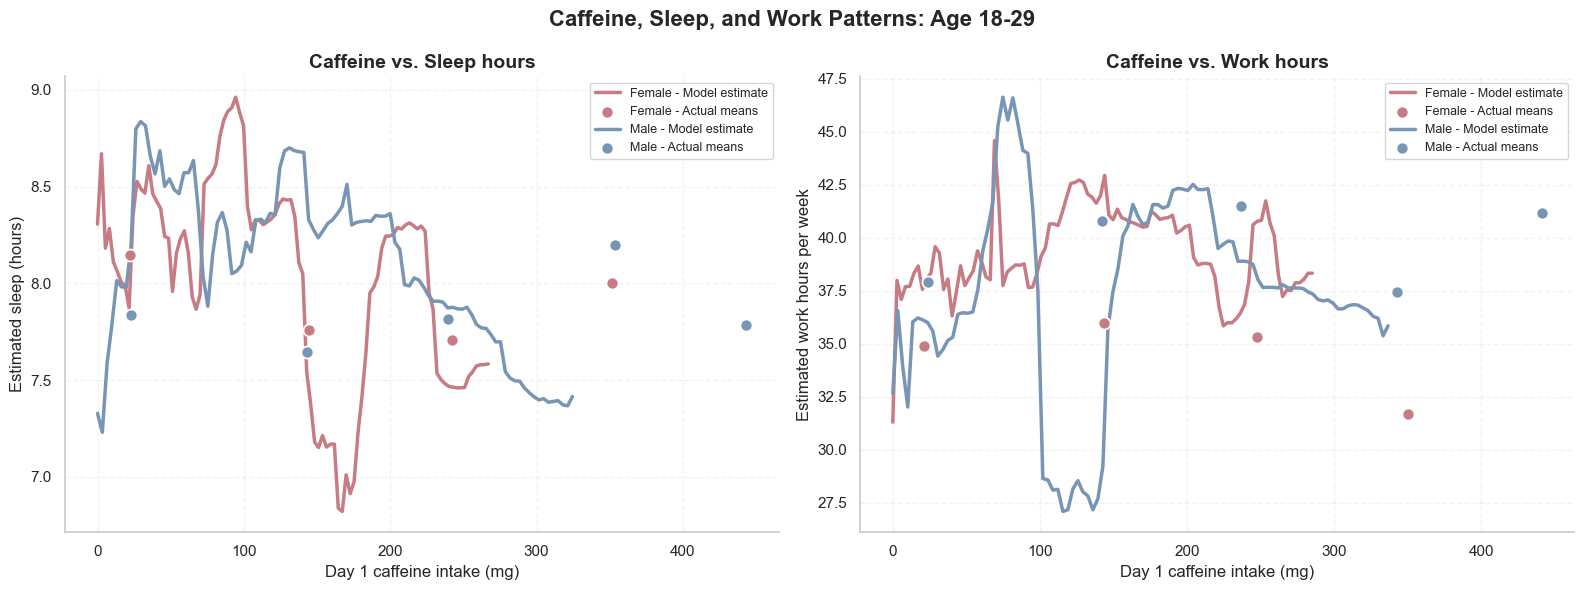

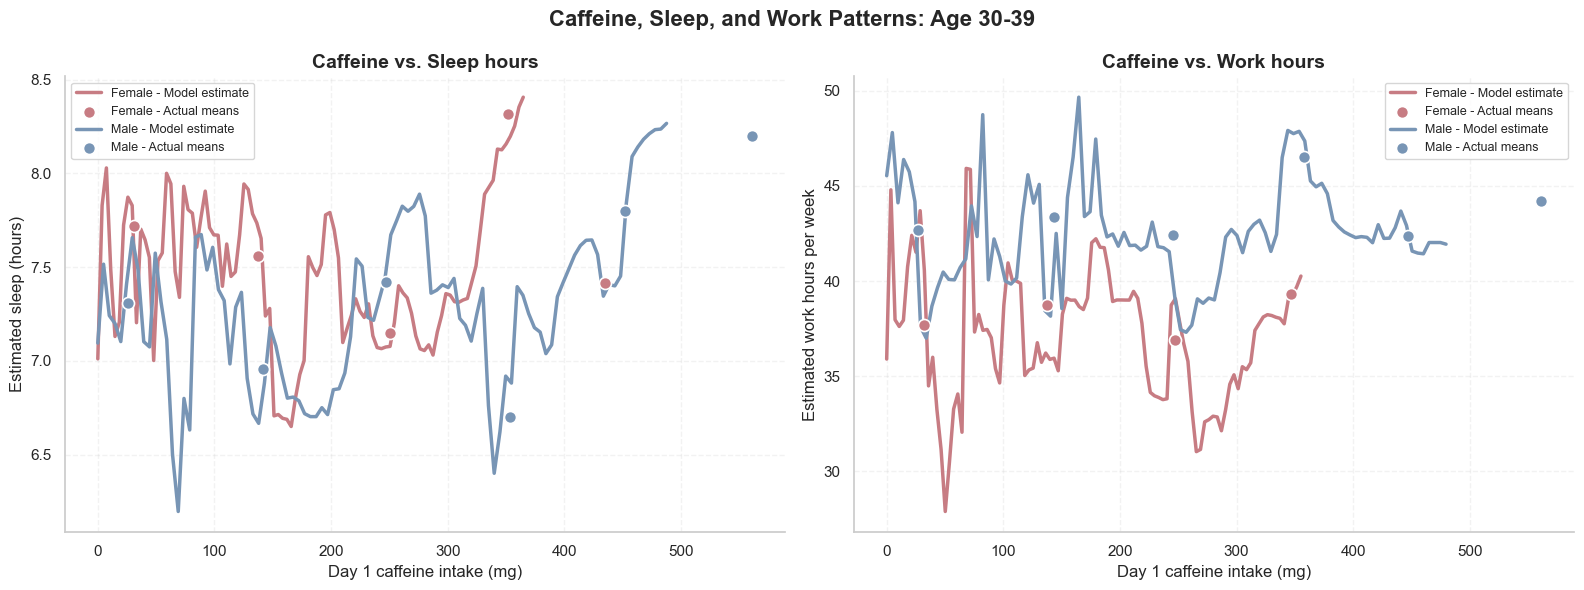

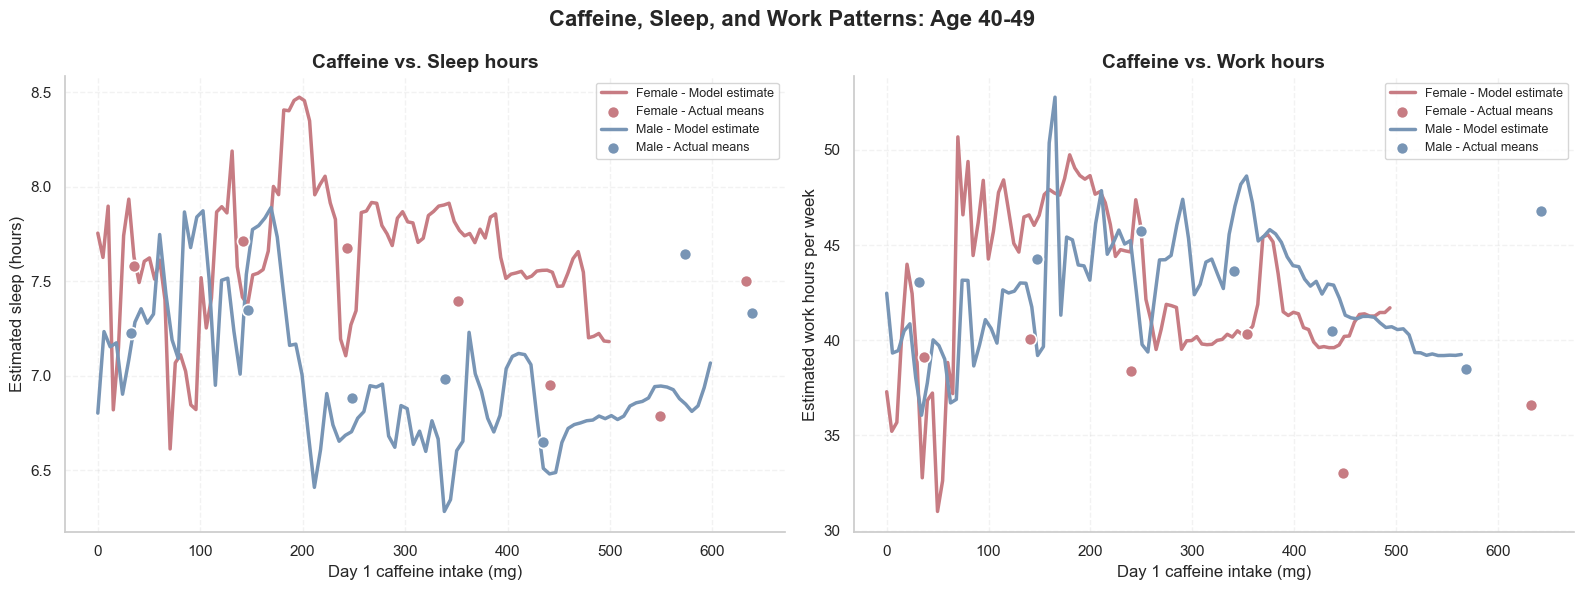

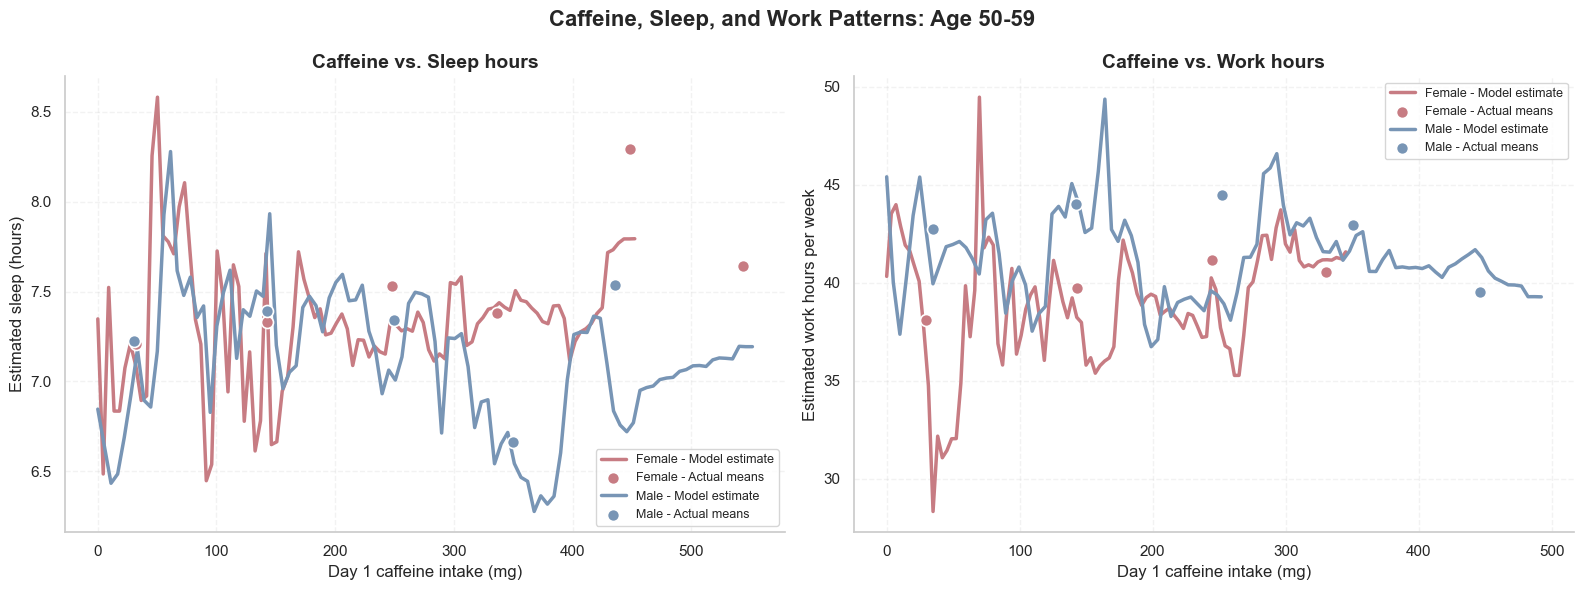

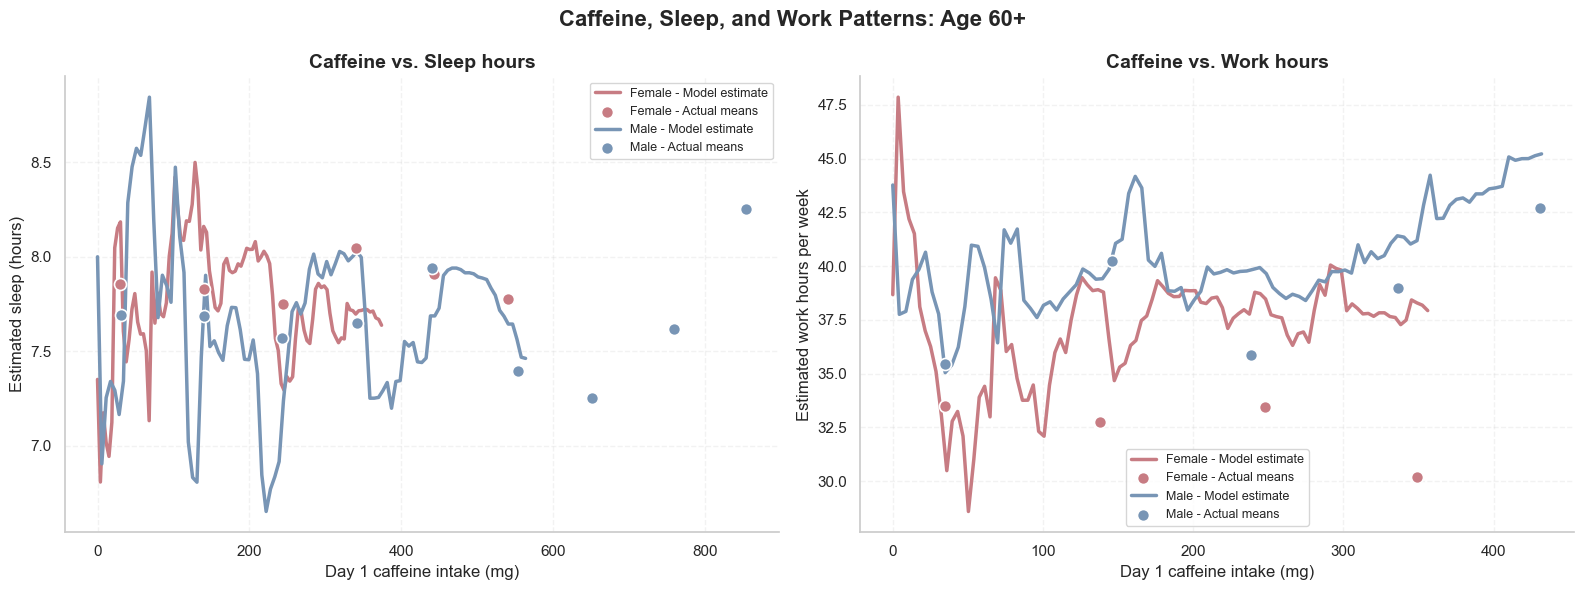

Each figure represents one age group.
Left graph = Sleep hours; right graph = Work hours.
Muted red = Female; muted blue = Male.
Lines = Random Forest model estimates.
Points = Actual means for each 100 mg caffeine range.
Only caffeine ranges with at least 5 participants are shown.
These graphs show associations, not causal effects.


In [ ]:
sns.set_theme(style="whitegrid", context="notebook")
sex_colors = {"Female": "#C77C83", "Male": "#7895B5"}

for age_group in age_labels:

    fig, axes = plt.subplots(1, 2, figsize = (16, 6))

    for ax, (outcome_name, target, y_label) in zip(axes, outcomes_to_plot):

        for sex_value in ["Female", "Male"]:

            # Select participants in this age and sex group
            group_data = demographic_ml_df[
                (demographic_ml_df["Sex"] == sex_value)
                & (demographic_ml_df["Age_Group"] == age_group)
                & demographic_ml_df["Age"].notna()
                & demographic_ml_df["Caffeine_mg"].notna()].dropna(subset = [target]).copy()

            if len(group_data) < minimum_group_size:
                continue

            color = sex_colors[sex_value]
            model = models.get((sex_value, target))

            if model is None:
                continue

            representative_age = group_data["Age"].median()
            caffeine_low = group_data["Caffeine_mg"].quantile(0.05)
            caffeine_high = group_data["Caffeine_mg"].quantile(0.95)

            if pd.isna(caffeine_low) or pd.isna(caffeine_high) or caffeine_low == caffeine_high:
                continue

            caffeine_values = np.linspace(caffeine_low, caffeine_high, 100)

            prediction_input = pd.DataFrame({"Caffeine_mg": caffeine_values, "Age": representative_age})

            predictions = model.predict(prediction_input)

            # Plot the Random Forest estimated line
            ax.plot(caffeine_values, predictions, color = color, linewidth = 2.5, label = f"{sex_value} - Model estimate")

            # Create caffeine ranges in 100 mg intervals
            group_data["Caffeine_Range"] = (np.floor(group_data["Caffeine_mg"] / 100) * 100)

            # Calculate actual mean caffeine and outcome for each range
            mean_data = (group_data.groupby("Caffeine_Range", observed = True).agg
                    (Mean_Caffeine = ("Caffeine_mg", "mean"),
                    Mean_Outcome = (target, "mean"),
                    Participants = (target, "count")).reset_index())

            # Only show ranges containing at least 5 participants
            mean_data = mean_data[mean_data["Participants"] >= 5]

            # Plot actual mean points
            ax.scatter(
                mean_data["Mean_Caffeine"], mean_data["Mean_Outcome"],
                color = color, edgecolor = "white", linewidth = 1.2, s = 75, zorder = 5, label = f"{sex_value} - Actual means")

        ax.set_title(f"Caffeine vs. {outcome_name}", fontsize = 14, fontweight = "bold")

        ax.set_xlabel("Day 1 caffeine intake (mg)")
        ax.set_ylabel(y_label)

        ax.legend(fontsize = 9)
        ax.grid(True, linestyle = "--", alpha = 0.25)

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    fig.suptitle(f"Caffeine, Sleep, and Work Patterns: Age {age_group}", fontsize = 16, fontweight = "bold")

    plt.tight_layout()
    plt.show()


print("Each figure represents one age group.")
print("Left graph = Sleep hours; right graph = Work hours.")
print("Muted red = Female; muted blue = Male.")
print("Lines = Random Forest model estimates.")
print("Points = Actual means for each 100 mg caffeine range.")
print("Only caffeine ranges with at least 5 participants are shown.")
print("These graphs show associations, not causal effects.")


## 14. Review classification performance

Accuracy alone can hide poor performance on less common response categories. Review precision, recall, and F1-score for each response category in the held-out test set.

In [ ]:
for outcome_name, (target, task) in targets.items():
    if task == "classification":
        X_test, y_test, predictions = test_data[outcome_name]["Caffeine + age + sex"]
        print("\\n", outcome_name)
        print(classification_report(y_test, predictions, zero_division = 0))

\n Focus difficulty
              precision    recall  f1-score   support

         0.0       0.83      0.77      0.80       800
         1.0       0.12      0.14      0.13        99
         2.0       0.03      0.07      0.05        29
         3.0       0.04      0.07      0.05        30

    accuracy                           0.66       958
   macro avg       0.26      0.26      0.26       958
weighted avg       0.71      0.66      0.68       958

\n Worry/anxiety frequency
              precision    recall  f1-score   support

         1.0       0.22      0.26      0.24       150
         2.0       0.19      0.25      0.22       140
         3.0       0.08      0.11      0.09       121
         4.0       0.33      0.22      0.27       337
         5.0       0.27      0.28      0.27       235

    accuracy                           0.23       983
   macro avg       0.22      0.22      0.22       983
weighted avg       0.25      0.23      0.24       983



## 15. How to interpret the results

- Use the caffeine-range tables and plots to describe how observed outcomes differ across caffeine-intake groups.
- Use the caffeine-only model to see how much predictive information caffeine provides by itself.
- Compare caffeine-only with age-and-sex and caffeine-plus-age-and-sex models to see whether caffeine adds predictive value.
- Use the dose-pattern curves to explore how the fitted model's estimates change across caffeine levels while age and sex are held constant.
- For sleep and work, lower MAE/RMSE means more accurate predictions. For focus and worry/anxiety, review weighted F1 and the per-category classification report.
- A model can identify patterns without proving that caffeine causes an outcome. Other factors not included in the data may explain some of the observed relationships.
- Caffeine is based on one day of dietary recall, so it may not represent usual intake.
- Focus difficulty is based on a depression-questionnaire item about trouble concentrating. Worry/anxiety frequency is not a direct validated stress scale.
- NHANES has a complex survey design. These ordinary models are exploratory and should not be described as population-representative estimates.